# Baseline model: day-ahead naive forecast

Before fitting any statistical or ML model, we need a benchmark that costs nothing to train.

Forecast the 24 hourly values of the next day using the last value known at forecast time. The simplest forecast that respects this rule is the **naive one-day forecast**.

We compare it against the actual demand and against RTE's own day-ahead forecast (`rte_forecast_d1_mw`), which is the benchmark we are ultimately trying to beat.

Metrics and splits come from the shared `scripts/evaluation.py` module so every model notebook in this project is scored the same way (see `readme.md`).

## Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path("..").resolve()))
from scripts.evaluation import load_data, score, save_result, walk_forward_folds

plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.grid": True})

DATA_DIR = Path("../data")
RESULTS_DIR = Path("../results")

## Load the data

One row per hour, 2019-01-01 to 2026-06-30, UTC. `load_data` converts to `Europe/Paris` local time (demand follows local daily/weekly habits, not UTC), sorts, and drops the 7 DST-transition rows with missing load/RTE forecast.

In [2]:
elec = load_data(DATA_DIR)
print(f"{len(elec):,} hourly rows, {elec.index.min()} to {elec.index.max()}")
elec.head()

65,703 hourly rows, 2019-01-01 01:00:00+01:00 to 2026-06-30 23:00:00+02:00


,load_mw,rte_forecast_d1_mw,temperature_c
datetime_local,,,
2019-01-01 01:00:00+01:00,60826.0,60838.0,5.85
2019-01-01 02:00:00+01:00,59786.0,59500.0,6.35
2019-01-01 03:00:00+01:00,56622.0,56012.0,5.91
2019-01-01 04:00:00+01:00,53920.0,53300.0,5.70
2019-01-01 05:00:00+01:00,52972.0,52188.0,5.72


## Walk-forward validation

Single holdout hides whether a model's score is a fluke of one period. We instead use **walk-forward, quarterly, expanding-window validation** over the same test year as before (2025-07-01 -> 2026-06-30), split into 4 quarterly folds:

- fold 1: train <= 2025-06-30 23:00, test = Jul-Sep 2025
- fold 2: train <= 2025-09-30 23:00, test = Oct-Dec 2025
- fold 3: train <= 2025-12-31 23:00, test = Jan-Mar 2026
- fold 4: train <= 2026-03-31 23:00, test = Apr-Jun 2026

**Note:** the naive and RTE forecasts have no parameters to fit, so the `train` half of each fold isn't actually used to fit anything here - it exists so the fold boundaries are defined consistently with models that *will* need to fit on it (SARIMAX, LightGBM, built later). This way all models in `results/` are compared on exactly the same test windows.

In [3]:
folds = list(walk_forward_folds(elec, n_folds=4, window="expanding"))
for fold_idx, train, test in folds:
    print(f"fold {fold_idx}: train {train.index.min()} -> {train.index.max()} ({len(train):,}h)  "
          f"test {test.index.min()} -> {test.index.max()} ({len(test):,}h)")

fold 1: train 2019-01-01 01:00:00+01:00 -> 2025-06-30 23:00:00+02:00 (56,944h)  test 2025-07-01 00:00:00+02:00 -> 2025-09-30 23:00:00+02:00 (2,208h)
fold 2: train 2019-01-01 01:00:00+01:00 -> 2025-09-30 23:00:00+02:00 (59,152h)  test 2025-10-01 00:00:00+02:00 -> 2025-12-31 23:00:00+01:00 (2,208h)
fold 3: train 2019-01-01 01:00:00+01:00 -> 2025-12-31 23:00:00+01:00 (61,360h)  test 2026-01-01 00:00:00+01:00 -> 2026-03-31 23:00:00+02:00 (2,159h)
fold 4: train 2019-01-01 01:00:00+01:00 -> 2026-03-31 23:00:00+02:00 (63,519h)  test 2026-04-01 00:00:00+02:00 -> 2026-06-30 23:00:00+02:00 (2,184h)


## The naive day-ahead forecasts

`load_mw.shift(24)` puts the value from 24 hours ago on the current row - exactly the lag-24 naive forecast, and the shortest lag that respects the horizon rule. We also keep the weekly naive (lag 168, "same hour last week") as a cheap secondary reference, and RTE's own published day-ahead forecast as the external benchmark.

In [4]:
naive_24_full = elec["load_mw"].shift(24)
naive_168_full = elec["load_mw"].shift(168)
rte_full = elec["rte_forecast_d1_mw"]
actual_full = elec["load_mw"]

forecast_series = {
    "naive_day_ahead": naive_24_full,
    "seasonal_naive_weekly": naive_168_full,
    "rte_benchmark": rte_full,
}

## Score each forecast, per fold

In [5]:
per_model_folds = {name: [] for name in forecast_series}

for fold_idx, train, test in folds:
    actual_test = actual_full.loc[test.index]
    for name, fc_full in forecast_series.items():
        fc_test = fc_full.loc[test.index]
        metrics = score(actual_test, fc_test)
        per_model_folds[name].append({
            "fold": fold_idx,
            "train_start": str(train.index.min()),
            "train_end": str(train.index.max()),
            "test_start": str(test.index.min()),
            "test_end": str(test.index.max()),
            "metrics": metrics,
        })

for name, fold_results in per_model_folds.items():
    print(f"\n{name}")
    for fr in fold_results:
        m = fr["metrics"]
        print(f"  fold {fr['fold']}: MAE={m['MAE_MW']:.1f}  RMSE={m['RMSE_MW']:.1f}  MAPE={m['MAPE_pct']:.2f}%")


naive_day_ahead
  fold 1: MAE=1955.8  RMSE=2986.8  MAPE=4.58%
  fold 2: MAE=2621.2  RMSE=3802.0  MAPE=4.83%
  fold 3: MAE=2591.2  RMSE=3702.6  MAPE=4.31%
  fold 4: MAE=2421.6  RMSE=3601.8  MAPE=5.44%

seasonal_naive_weekly
  fold 1: MAE=1603.5  RMSE=2158.1  MAPE=3.66%
  fold 2: MAE=3924.3  RMSE=6106.8  MAPE=6.67%
  fold 3: MAE=5122.8  RMSE=6510.2  MAPE=8.52%
  fold 4: MAE=3102.3  RMSE=4316.2  MAPE=6.85%

rte_benchmark
  fold 1: MAE=1220.7  RMSE=1554.7  MAPE=2.79%
  fold 2: MAE=1438.4  RMSE=1781.1  MAPE=2.68%
  fold 3: MAE=1553.6  RMSE=1891.0  MAPE=2.60%
  fold 4: MAE=1547.0  RMSE=1886.6  MAPE=3.37%


## Mean metrics across folds

In [6]:
mean_table = pd.DataFrame({
    name: {m: np.mean([fr["metrics"][m] for fr in fold_results]) for m in ["MAE_MW", "RMSE_MW", "MAPE_pct"]}
    for name, fold_results in per_model_folds.items()
})
mean_table.round(2)

,naive_day_ahead,seasonal_naive_weekly,rte_benchmark
MAE_MW,2397.46,3438.22,1439.91
RMSE_MW,3523.30,4772.81,1778.33
MAPE_pct,4.79,6.42,2.86


## Plot: one winter week

Winter evenings are where forecast errors are the most expensive (readme), so that is the window worth a visual check. This plot is not fold-specific - it's a diagnostic snapshot, not a scored evaluation.

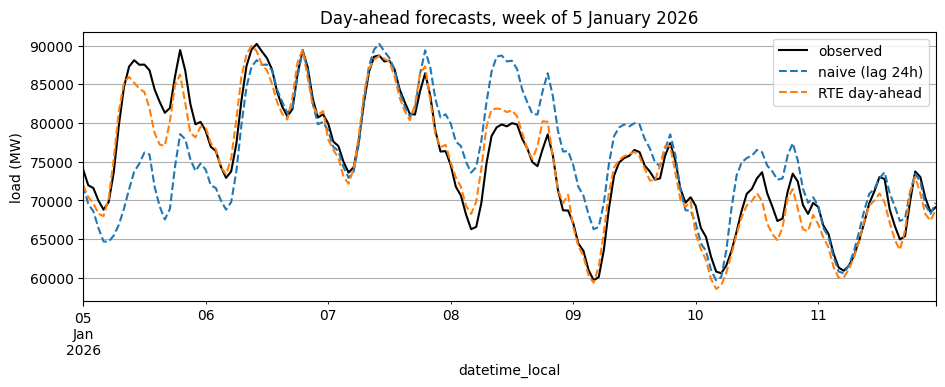

In [7]:
week = slice("2026-01-05", "2026-01-11")

fig, ax = plt.subplots()
actual_full.loc[week].plot(ax=ax, label="observed", color="black", linewidth=1.5)
naive_24_full.loc[week].plot(ax=ax, label="naive (lag 24h)", linestyle="--")
rte_full.loc[week].plot(ax=ax, label="RTE day-ahead", linestyle="--")
ax.set_ylabel("load (MW)")
ax.set_title("Day-ahead forecasts, week of 5 January 2026")
ax.legend()
plt.show()

## What we see

Mean MAE across the 4 walk-forward folds (MW):

| model | mean MAE | mean RMSE | mean MAPE |
|---|---|---|---|
| naive (lag 24h) | 2397 | 3523 | 4.79% |
| seasonal naive (lag 168h) | 3438 | 4773 | 6.42% |
| RTE day-ahead | 1440 | 1778 | 2.86% |

The naive lag-24 forecast is consistently a far better reference than the weekly naive: demand is close from one day to the next, but a lot can change in a week. RTE's own forecast, which uses weather and calendar information, beats both naive baselines in every single fold - this is the bar the next models (SARIMAX, LightGBM) need to clear.

Performance is **not** stable across folds. For the naive forecasts, fold 3 (Jan-Mar, winter) and fold 2 (Oct-Dec) are clearly worse than fold 1 (Jul-Sep, summer): naive MAE goes from 1956 MW in fold 1 up to 2621 and 2591 MW in folds 2 and 3, and the seasonal-naive MAPE roughly doubles from 3.7% in fold 1 to 8.5% in fold 3. Demand is more volatile in cold weather (heating load swings with temperature), so day-to-day and week-to-week changes are larger and the naive forecasts suffer more. RTE's forecast is comparatively stable across folds (MAE 1221-1554 MW, a much narrower spread) since it already accounts for temperature and calendar effects - exactly the kind of fold-by-fold pattern a single holdout would have hidden.

The MAPE is safe to use here (demand is never close to 0 MW), unlike for the temperature series in `01_data_audit.ipynb`.

## Save results

One result file per model, named after the model, so the final comparison notebook can simply load every file in `results/`. Each file now stores per-fold metrics plus their mean/std, under the walk-forward validation scheme, rather than a single holdout metrics dict.

In [8]:
descriptions = {
    "naive_day_ahead": "Naive forecast: load(t) = load(t-24h)",
    "seasonal_naive_weekly": "Seasonal naive: load(t) = load(t-168h)",
    "rte_benchmark": "RTE's published day-ahead forecast (external benchmark)",
}

for name, fold_results in per_model_folds.items():
    save_result(
        name,
        descriptions[name],
        validation="walk-forward quarterly, expanding window",
        fold_results=fold_results,
        results_dir=RESULTS_DIR,
    )

saved ..\results\naive_day_ahead.json
saved ..\results\seasonal_naive_weekly.json
saved ..\results\rte_benchmark.json
